# 🛣️ Road Lane Detection- Learning camera based ADAS working in cars and its use case on Indian Roads

**Goal:** find lane markings on a road photo – **white or yellow, straight or curvy, dashed or solid** – and also show **which part of the road is the lane**.

### The big picture
One single AI model is not enough here, because none of our datasets contains *everything*. So we build the project in three segments and let them work together:

| Segments | What it finds | Learns from | Why we need it |
|---|---|---|---|
| 🟥 **YOLO detector** | small boxes around lane-marking pieces (dashes, segments) | your first dataset (50 photos with boxes) | learns what real paint on real roads looks like |
| 🟩 **U-Net segmenter** | the *road / lane area* (ego lane + other lanes) | your KITTI dataset (289 photos with masks) | tells us *where the road is*, so we ignore trees, sky, poles |
| 🟨 **Colour + curve finder** | white & yellow paint, then draws smooth straight/curved lines | no training needed – maths + colour rules | the datasets have almost no yellow or curved examples, so this part covers them |

**Honest note about the data:** the KITTI masks show *where the lane is*, not the painted lines, and neither dataset has many yellow lines. That is exactly why the third segemnt exists.

**Before you start:** `Runtime → Change runtime type → T4 GPU`, then run the cells from top to bottom (`Shift + Enter`). Total time ≈ 30–45 minutes, most of it training.

## Step 1 – Prepare the computer (install the tools)

**What we are doing:** checking that a GPU is switched on and installing two libraries.

**What the code does:**
- `nvidia-smi` shows the GPU. Training on a GPU is ~20× faster than on a normal CPU.
- `ultralytics` gives us **YOLOv8** (the box detector).
- `segmentation-models-pytorch` gives us **U-Net** (the road-area model) with ready-made pretrained parts.

**What you should see:** a line like `Tesla T4` and `GPU available: True`. If it says `False`, go to *Runtime → Change runtime type* and pick a GPU.

In [3]:
!nvidia-smi -L
!pip install -q ultralytics segmentation-models-pytorch
import torch
device = "cuda" if torch.cuda.is_available() else "cpu"
print("GPU available:", torch.cuda.is_available())
if device == "cpu":
    print("⚠️ No GPU found. Switch to a GPU runtime or training will take hours.")

GPU 0: Tesla T4 (UUID: GPU-0258b618-7ae6-d899-871b-d0a1a77ac1d0)
GPU available: True


## Step 2 – Upload your datasets

**What we are doing:** getting your zip files into Colab and unpacking each one into its own folder.

**What the code does:**
1. Opens an upload window – **select all your zips at once** (the lane-box dataset and the KITTI dataset).
2. Compares the files by content. If you upload the same dataset twice (like `archive.zip` and `archive_1.zip`, which are identical), the copy is skipped.
3. Unzips each dataset into `/content/raw/<name>`.
4. Looks inside each folder and decides **what kind of dataset it is**:
   - `boxes` → photos + XML files with boxes around lane marks
   - `lane_masks` → KITTI-style photos + colour mask pictures

**What you should see:** a short list such as `{'archive': 'boxes', 'archive__1_': 'lane_masks'}`.

*Tip:* the uploads vanish when Colab restarts – just run this cell again.

In [4]:
import os, re, glob, zipfile, hashlib

UPLOAD_MORE = True          # True = open the upload window. Set False if the zips are already in /content
RAW_ROOT = "/content/raw"
os.makedirs(RAW_ROOT, exist_ok=True)

if UPLOAD_MORE:
    from google.colab import files
    files.upload()

def md5(path):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

seen = {}
for zp in sorted(glob.glob("/content/*.zip")):
    digest = md5(zp)
    if digest in seen:
        print(f"Skipping {os.path.basename(zp)} – identical to {seen[digest]}")
        continue
    seen[digest] = os.path.basename(zp)
    name = re.sub(r"[^A-Za-z0-9]+", "_", os.path.splitext(os.path.basename(zp))[0]).strip("_")
    dest = f"{RAW_ROOT}/{name}"
    if os.path.isdir(dest):
        print("Already extracted:", name); continue
    with zipfile.ZipFile(zp) as z:
        z.extractall(dest)
    print("Extracted:", name)

def dataset_kind(folder):
    if glob.glob(f"{folder}/**/gt_image_2", recursive=True): return "lane_masks"
    if glob.glob(f"{folder}/**/*.xml", recursive=True):      return "boxes"
    return "unknown"

DATASETS = {d: dataset_kind(f"{RAW_ROOT}/{d}") for d in sorted(os.listdir(RAW_ROOT))}
print("\nDatasets found:", DATASETS)

Saving archive (1).zip to archive (1).zip
Saving archive.zip to archive.zip
Extracted: archive_1
Extracted: archive

Datasets found: {'archive': 'boxes', 'archive_1': 'lane_masks'}


---
# PART A – Helper 1: the YOLO lane-marking detector

## Step 3 – Convert the box labels into the format YOLO understands

**What we are doing:** your boxes are stored as `.xml` files (Pascal VOC style). YOLO can only read `.txt` files, so we translate them.

**What a YOLO label line means:** `0  0.52  0.61  0.03  0.02` → *class 0 (road_line), box centre at 52 % across and 61 % down the picture, 3 % wide, 2 % tall.* All numbers are fractions of the image size.

**What the code does, in plain words:**
1. Matches every XML file to its photo.
2. **Straightens phone photos.** Phones save photos sideways with a hidden "rotate me" tag. Your boxes were drawn on the *rotated* picture, so we apply the rotation first (otherwise most boxes would land in the wrong place).
3. **Shrinks big photos** (3000–4600 px) to 1280 px so training is fast.
4. Converts each box to YOLO numbers and saves it.
5. Splits the photos **80 % for learning / 20 % for exam**. The model never sees the exam photos while learning, so exam marks tell us the *honest* accuracy.
6. Writes `data.yaml`, the "map" file that tells YOLO where everything is.

**Class settings:** right now there is one class, `road_line`. If you later add a dataset with other names (e.g. `yellow_line`), add them to `NAME_MAP` – any name not listed is skipped and reported at the end, so nothing disappears silently.

**What you should see:** a line per dataset with the number of images and boxes (your dataset: 50 images, 172 boxes).

In [5]:
import glob, random, shutil
import xml.etree.ElementTree as ET
from PIL import Image, ImageOps
from collections import Counter

OUT_DIR  = "/content/yolo_data"
MAX_SIDE = 1280
VAL_FRAC = 0.2
SEED     = 42

# ---- classes: edit here if a new dataset uses other names -----------------------------
CLASS_NAMES = ["road_line"]
NAME_MAP    = {"road_line": 0}     # name in the XML  ->  class number
YOLO_ID_MAP = {0: 0}               # only for datasets already in YOLO .txt format
# ----------------------------------------------------------------------------------------

shutil.rmtree(OUT_DIR, ignore_errors=True)
for s in ("train", "val"):
    os.makedirs(f"{OUT_DIR}/images/{s}"); os.makedirs(f"{OUT_DIR}/labels/{s}")

def find_images(folder):
    return {os.path.splitext(os.path.basename(p))[0]: p
            for p in glob.glob(f"{folder}/**/*", recursive=True)
            if p.lower().endswith((".jpg", ".jpeg", ".png"))}

def voc_labels(xml_path):
    root = ET.parse(xml_path).getroot()
    xw, xh = int(root.find("size/width").text), int(root.find("size/height").text)
    out = []
    for obj in root.findall("object"):
        nm = (obj.findtext("name") or obj.findtext("n") or "").strip()   # some tools write <n>
        if nm not in NAME_MAP:
            skipped[nm] += 1; continue
        b = obj.find("bndbox")
        x1, y1, x2, y2 = (float(b.find(k).text) for k in ("xmin", "ymin", "xmax", "ymax"))
        out.append((NAME_MAP[nm], x1, y1, x2, y2))
    return out, xw, xh

def yolo_labels(txt_path):
    out = []
    for line in open(txt_path):
        p = line.split()
        if len(p) != 5: continue
        cid = int(float(p[0]))
        if cid not in YOLO_ID_MAP:
            skipped[f"yolo_id_{cid}"] += 1; continue
        out.append((YOLO_ID_MAP[cid],) + tuple(map(float, p[1:])))
    return out

skipped, summary = Counter(), {}
for ds, kind in DATASETS.items():
    if kind != "boxes": continue
    folder = f"{RAW_ROOT}/{ds}"
    imgs = find_images(folder)
    xmls = {os.path.splitext(os.path.basename(p))[0]: p for p in glob.glob(f"{folder}/**/*.xml", recursive=True)}
    stems = sorted(s for s in imgs if s in xmls)
    random.Random(SEED).shuffle(stems)
    n_val = max(1, int(len(stems) * VAL_FRAC))
    n_img = n_box = 0
    for i, stem in enumerate(stems):
        s = "val" if i < n_val else "train"
        img = ImageOps.exif_transpose(Image.open(imgs[stem])).convert("RGB")   # fix phone rotation
        W, H = img.size
        vb, xw, xh = voc_labels(xmls[stem])
        if (xw, xh) != (W, H):
            print(f"[{ds}] size mismatch XML vs image:", stem, (xw, xh), (W, H))
        boxes = []
        for c, x1, y1, x2, y2 in vb:
            x1, x2 = max(0, min(x1, xw)), max(0, min(x2, xw))
            y1, y2 = max(0, min(y1, xh)), max(0, min(y2, xh))
            if x2 - x1 < 1 or y2 - y1 < 1: continue
            boxes.append((c, (x1+x2)/2/xw, (y1+y2)/2/xh, (x2-x1)/xw, (y2-y1)/xh))
        scale = min(1.0, MAX_SIDE / max(W, H))
        if scale < 1:
            img = img.resize((round(W * scale), round(H * scale)), Image.LANCZOS)
        uid = f"{ds}_{stem}"
        img.save(f"{OUT_DIR}/images/{s}/{uid}.jpg", quality=95)
        with open(f"{OUT_DIR}/labels/{s}/{uid}.txt", "w") as f:
            f.write("\n".join(f"{c} {x:.6f} {y:.6f} {w:.6f} {h:.6f}" for c, x, y, w, h in boxes))
        n_img += 1; n_box += len(boxes)
    summary[ds] = (n_img, n_box)

names_yaml = "\n".join(f"  {i}: {n}" for i, n in enumerate(CLASS_NAMES))
open(f"{OUT_DIR}/data.yaml", "w").write(f"path: {OUT_DIR}\ntrain: images/train\nval: images/val\nnames:\n{names_yaml}\n")

for ds, (ni, nb_) in summary.items():
    print(f"{ds:20s} images: {ni:4d}   boxes: {nb_}")
print("TOTAL  train:", len(os.listdir(f"{OUT_DIR}/images/train")), " val:", len(os.listdir(f"{OUT_DIR}/images/val")))
if skipped:
    print("Skipped labels with unknown names:", dict(skipped))

archive              images:   50   boxes: 172
TOTAL  train: 40  val: 10


## Step 4 – Look at the data before training (sanity check)

**What we are doing:** drawing the converted boxes on a few photos. If the green boxes sit on the white paint, the conversion is right. If they float in the sky, something is wrong – better to know *now* than after 30 minutes of training.

**What you should see:** four road photos with green boxes on the lane paint.

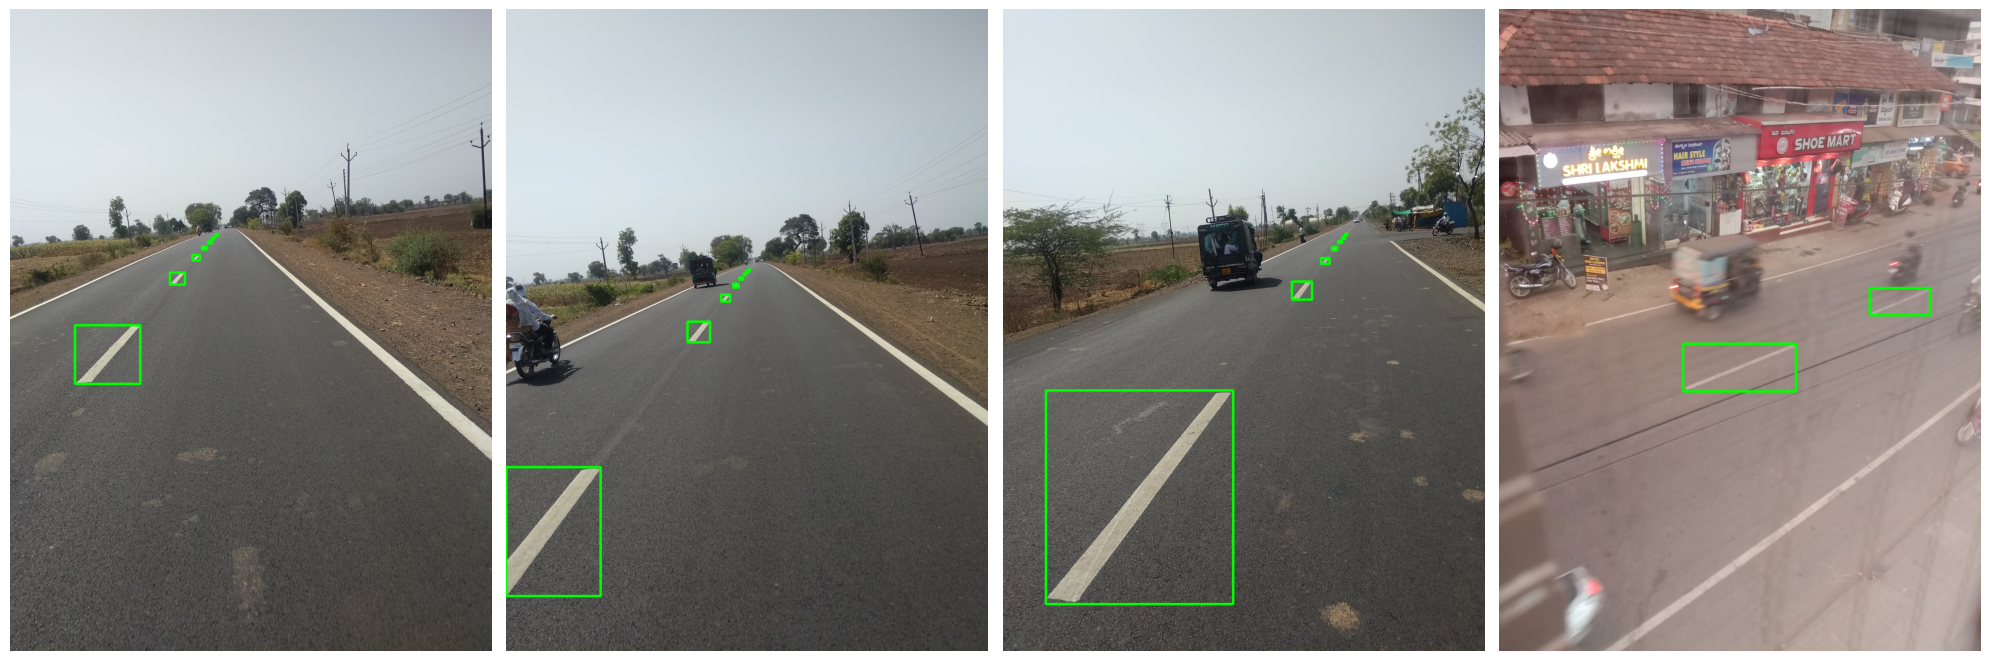

In [6]:
import cv2, numpy as np, matplotlib.pyplot as plt

files_ = sorted(glob.glob(f"{OUT_DIR}/images/train/*.jpg"))[:4]
fig, axes = plt.subplots(1, len(files_), figsize=(5 * len(files_), 8))
for ax, f in zip(np.atleast_1d(axes), files_):
    im = cv2.cvtColor(cv2.imread(f), cv2.COLOR_BGR2RGB); h, w = im.shape[:2]
    for line in open(f.replace("images", "labels").replace(".jpg", ".txt")):
        if not line.strip(): continue
        _, x, y, bw, bh = map(float, line.split())
        cv2.rectangle(im, (int((x-bw/2)*w), int((y-bh/2)*h)), (int((x+bw/2)*w), int((y+bh/2)*h)), (0, 255, 0), 4)
    ax.imshow(im); ax.axis("off")
plt.tight_layout(); plt.show()

## Step 5 – Train the YOLO detector

**What we are doing:** teaching YOLO what a lane-marking piece looks like.

**Key idea – transfer learning:** we do *not* start from zero. `yolov8s.pt` already knows edges, shapes and textures from millions of everyday photos. We only teach it the last bit: "this is lane paint". That is how 40 training photos can be enough.

**The settings, explained simply:**
| Setting | Meaning | Why this value |
|---|---|---|
| `imgsz=1280` | picture size fed to the model | paint pieces are tiny, so we keep high detail |
| `epochs=150` | how many times it studies the whole set | more rounds = better, up to a point |
| `patience=40` | stops early if the exam score hasn't improved for 40 rounds | saves time, avoids over-studying |
| `batch=8` | photos per step | fits a free T4 GPU (use 4 if you see *out of memory*) |
| `degrees, scale, mixup, hsv_*` | **augmentation**: random tilt, zoom, blend, colour change | with few photos this "fakes" thousands of different ones, which is the biggest accuracy boost |
| `cos_lr=True` | learning speed fades smoothly | usually gives a slightly better final score |

**What you should see:** a table updating every epoch. The numbers to watch are `mAP50` (higher is better, 1.0 = perfect). Expect 15–30 minutes. When done, the best version is saved automatically as `best.pt`.

In [7]:
from ultralytics import YOLO

MODEL = "yolov8s.pt"     # n = fastest, s = balanced, m = more accurate but slower (use batch=4 for m)

yolo_model = YOLO(MODEL)
yolo_model.train(
    data=f"{OUT_DIR}/data.yaml",
    epochs=150, patience=40, imgsz=1280, batch=8, workers=2, seed=42, cache="ram",
    cos_lr=True, close_mosaic=15,
    degrees=5.0, translate=0.1, scale=0.5, fliplr=0.5, mixup=0.1,
    hsv_h=0.02, hsv_s=0.7, hsv_v=0.4,
    project="/content/runs", name="markings", exist_ok=True,
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=15, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/yolo_data/data.yaml, degrees=5.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=150, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freez

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7b4f7124b690>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

## Step 6 – Grade the YOLO detector on the exam photos

**What we are doing:** measuring accuracy on photos the model never studied.

**How to read the numbers:**
- **Precision** – of all boxes it drew, what share were real paint. (Low = many false alarms.)
- **Recall** – of all real paint pieces, what share it found. (Low = it misses lines.)
- **mAP50** – one overall score (0–1) counting a box as correct if it overlaps the true box by ≥ 50 %.
- **mAP50-95** – the same but much stricter about exact box position.

Don't be alarmed by modest numbers: many labelled pieces are only a few pixels wide and are hard even for humans. That is one more reason we add helpers 2 and 3.

Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,125,971 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3068.3±490.7 MB/s, size: 447.8 KB)
val: Scanning /content/yolo_data/labels/val.cache... 10 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 10/10 3.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 1.4it/s 0.7s
                   all         10         32       0.48        0.5      0.482      0.274
Speed: 1.4ms preprocess, 38.0ms inference, 0.0ms loss, 0.9ms postprocess per image
Results saved to /content/runs/detect/val
Precision 0.480 | Recall 0.500 | mAP50 0.482 | mAP50-95 0.274


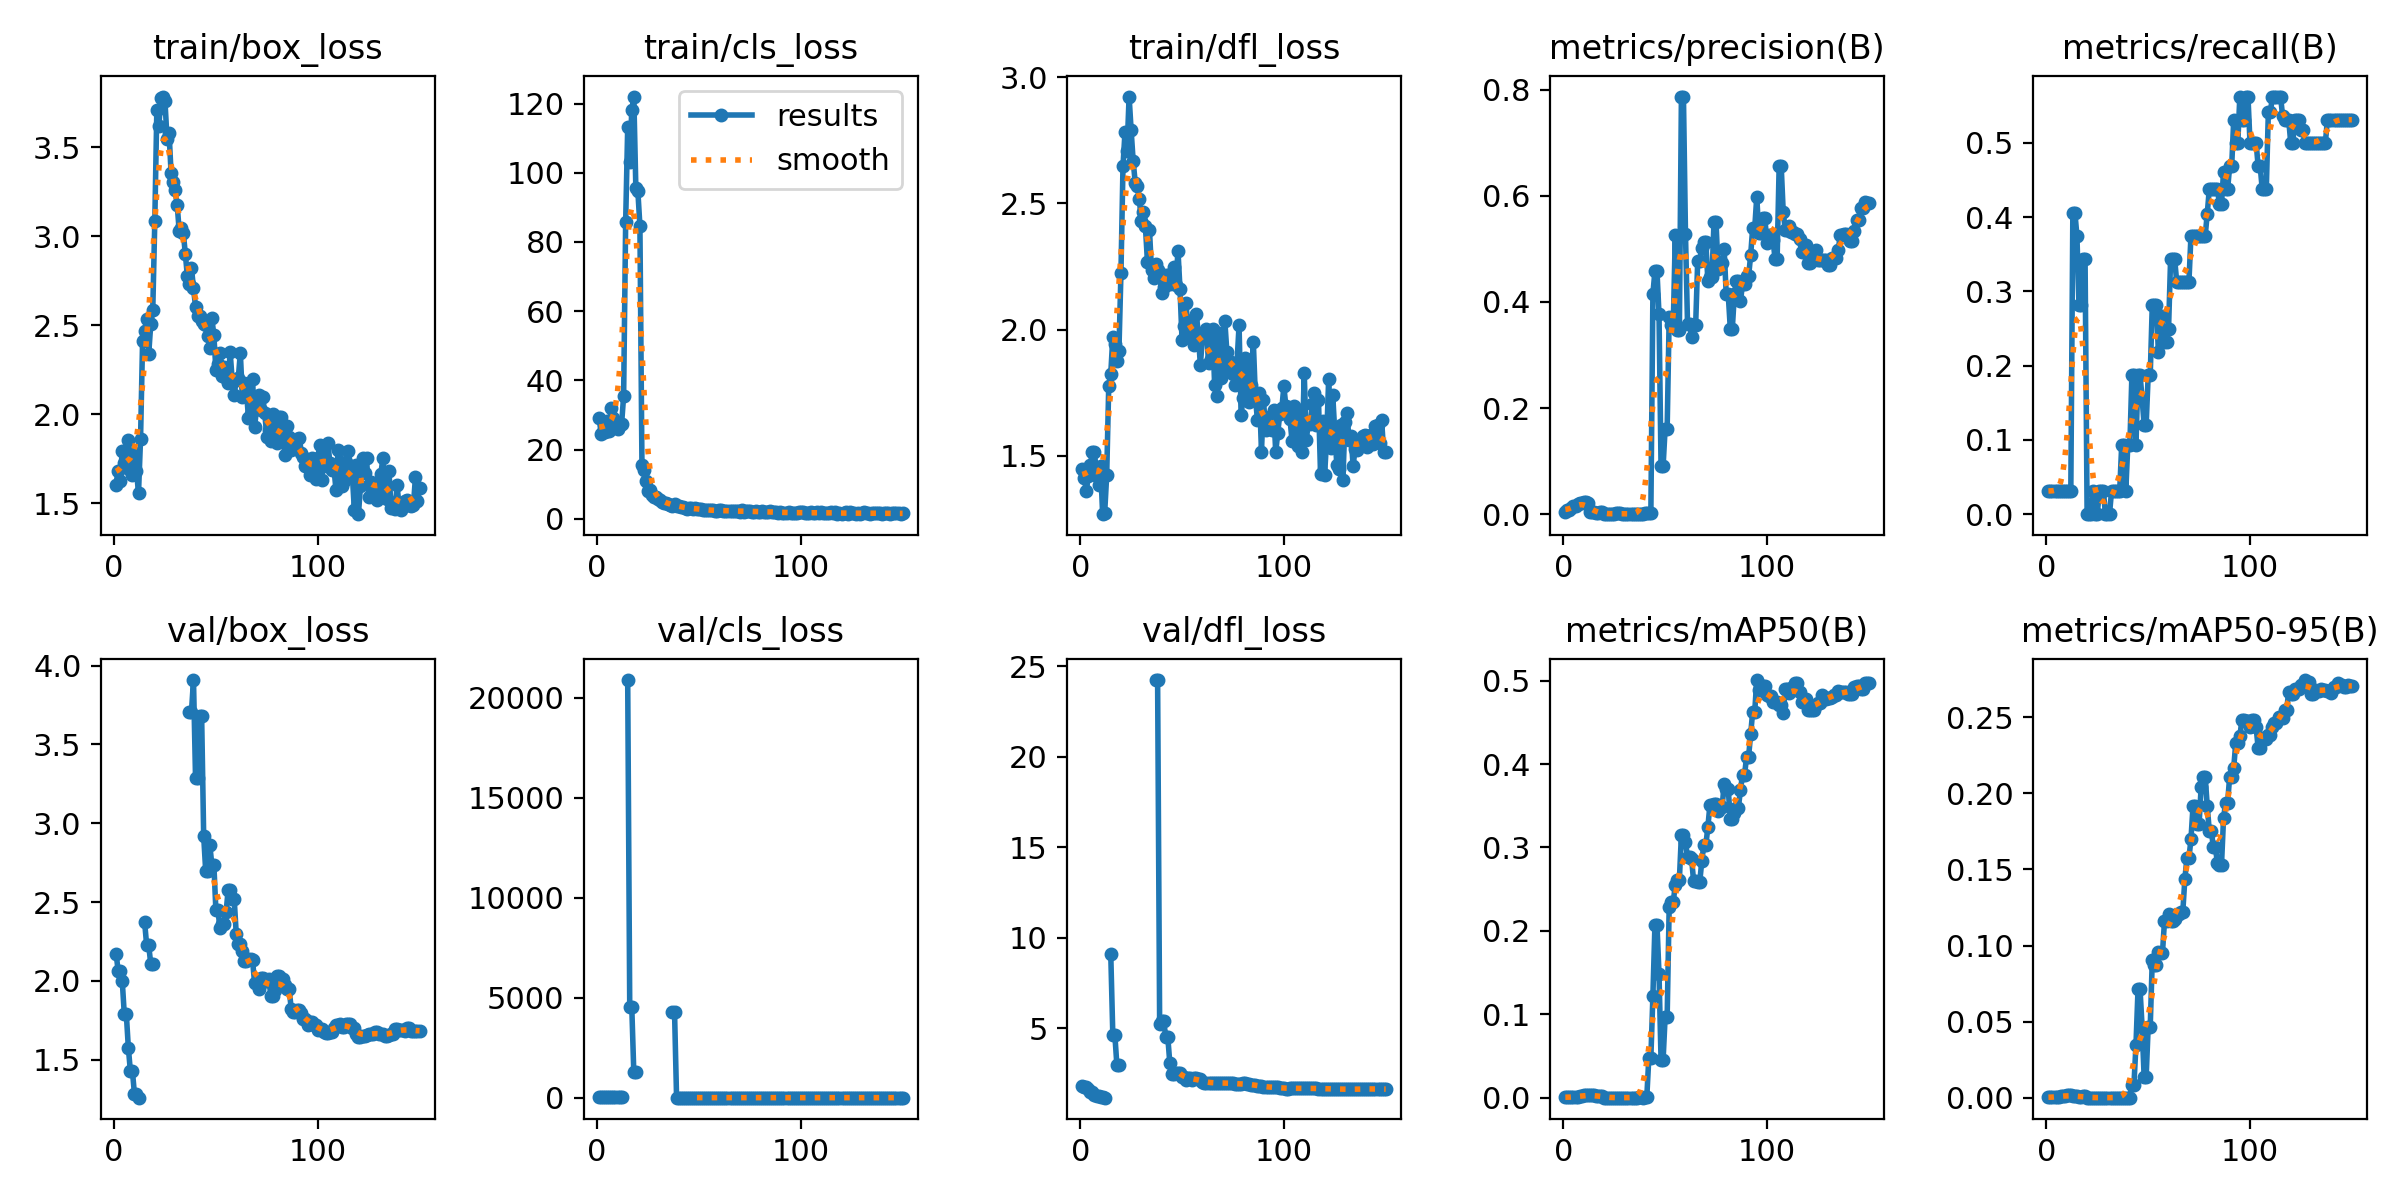

In [8]:
yolo_path = "/content/runs/markings/weights/best.pt"
yolo = YOLO(yolo_path)
m = yolo.val(data=f"{OUT_DIR}/data.yaml", imgsz=1280, split="val", verbose=False)
YOLO_MAP50 = float(m.box.map50)
print(f"Precision {m.box.mp:.3f} | Recall {m.box.mr:.3f} | mAP50 {m.box.map50:.3f} | mAP50-95 {m.box.map:.3f}")

from IPython.display import Image as IPImage, display
display(IPImage("/content/runs/markings/results.png", width=900))

---
# PART B – Helper 2: the U-Net road / lane-area segmenter

## Step 7 – Read the KITTI photos and masks

**What we are doing:** the KITTI dataset gives, for each road photo, a **mask picture** – a second image where each colour means something:
- 🟣 **magenta** = the lane *you* are driving in (ego lane)
- ⚫ **black** = other lanes (e.g. opposite direction)
- 🔴 **red** = everything else (sky, trees, buildings, sidewalks)

**What the code does:**
1. Pairs each photo with its mask (the mask file name is the photo name with `gt_` in front).
2. Turns the mask colours into simple numbers per pixel: `0` = background, `1` = ego lane, `2` = other lane. (The mask edges are slightly blurry, so we use "is the red/blue part bright or dark?" rules instead of exact colours.)
3. Splits 80 % for learning / 20 % for exam.
4. Shows a few examples so you can check the pairing.

**What you should see:** `Loaded 289 image/mask pairs` and 4 photos with a green (ego lane) / blue (other lane) tint.

Loaded 289 image/mask pairs, size (224, 224)
train: 232  val: 57


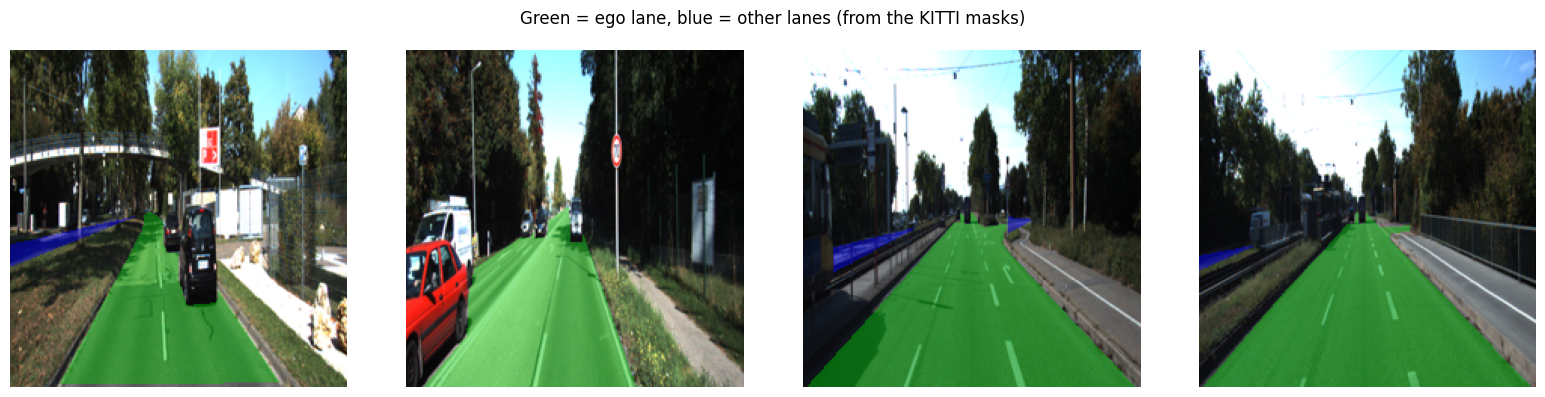

In [9]:
KITTI_DIRS = [d for d, k in DATASETS.items() if k == "lane_masks"]
assert KITTI_DIRS, "No KITTI-style dataset found – upload the zip that contains gt_image_2 folders."

def decode_mask(path):
    m = cv2.imread(path).astype(int)               # BGR
    B, R = m[..., 0], m[..., 2]
    cls = np.zeros(B.shape, np.uint8)               # 0 = background (red)
    cls[(R > 127) & (B > 127)] = 1                  # magenta = ego lane
    cls[(R <= 127) & (B <= 127)] = 2                # black   = other lane
    return cls

X_all, Y_all, names = [], [], []
for d in KITTI_DIRS:
    for img_dir in glob.glob(f"{RAW_ROOT}/{d}/**/training/image_2", recursive=True):
        gt_dir = img_dir.replace("image_2", "gt_image_2")
        for p in sorted(glob.glob(f"{img_dir}/*.png") + glob.glob(f"{img_dir}/*.jpg")):
            g = os.path.join(gt_dir, "gt_" + os.path.basename(p))
            if not os.path.exists(g): continue
            im = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
            X_all.append(cv2.resize(im, (224, 224))); Y_all.append(cv2.resize(decode_mask(g), (224, 224), interpolation=cv2.INTER_NEAREST))
            names.append(os.path.basename(p))
X_all, Y_all = np.stack(X_all), np.stack(Y_all)
print(f"Loaded {len(X_all)} image/mask pairs, size {X_all.shape[1:3]}")

idx = np.random.RandomState(42).permutation(len(X_all)); n_val = max(1, int(0.2 * len(idx)))
val_idx, train_idx = idx[:n_val], idx[n_val:]
print("train:", len(train_idx), " val:", len(val_idx))

TINT = {1: (0, 200, 0), 2: (0, 0, 255)}
def tint(img_rgb, cls, alpha=0.45):
    out = img_rgb.copy().astype(np.float32)
    for k, col in TINT.items():
        out[cls == k] = (1 - alpha) * out[cls == k] + alpha * np.array(col, np.float32)
    return out.astype(np.uint8)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, i in zip(axes, train_idx[:4]):
    ax.imshow(tint(X_all[i], Y_all[i])); ax.axis("off")
plt.suptitle("Green = ego lane, blue = other lanes (from the KITTI masks)"); plt.tight_layout(); plt.show()

## Step 8 – Build the U-Net and its training "lesson plan"

**What U-Net is:** a model that looks at a photo and gives a *label for every pixel* ("this pixel is ego lane / other lane / background"). That is called **segmentation**.

**What the code sets up:**
- **Pretrained ResNet-34 encoder (`encoder_weights="imagenet"`)** – again transfer learning: the "eyes" of the model already know how to see.
- **Augmentation** (applied randomly while learning): mirror flip, random zoom-crop, brightness/contrast change. With only 231 training photos this stops the model from just memorising them.
- **Loss = Cross-Entropy + Dice** – a "how wrong are you" score. Dice is added because the *other lane* class is small and would otherwise be ignored.
- **mIoU metric** – *Intersection over Union*: for each class, (area predicted AND true) ÷ (area predicted OR true). 1.0 = perfect. We average over the three classes.

Nothing visible happens here except a model summary line – the learning happens in the next step.

In [10]:
import random, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import segmentation_models_pytorch as smp

IMG = 224
MEAN = np.array([0.485, 0.456, 0.406], np.float32); STD = np.array([0.229, 0.224, 0.225], np.float32)

def to_tensor(img_rgb):
    x = (img_rgb.astype(np.float32) / 255.0 - MEAN) / STD
    return torch.from_numpy(x.transpose(2, 0, 1))

class RoadSet(Dataset):
    def __init__(self, X, Y, train): self.X, self.Y, self.train = X, Y, train
    def __len__(self): return len(self.X)
    def __getitem__(self, i):
        img, m = self.X[i].copy(), self.Y[i].copy()
        if self.train:
            if random.random() < 0.5: img, m = img[:, ::-1], m[:, ::-1]               # mirror
            s = random.uniform(0.75, 1.0); ch = cw = int(IMG * s)                       # random zoom-crop
            y0, x0 = random.randint(0, IMG - ch), random.randint(0, IMG - cw)
            img = cv2.resize(np.ascontiguousarray(img[y0:y0+ch, x0:x0+cw]), (IMG, IMG), interpolation=cv2.INTER_LINEAR)
            m   = cv2.resize(np.ascontiguousarray(m[y0:y0+ch, x0:x0+cw]),   (IMG, IMG), interpolation=cv2.INTER_NEAREST)
            a, b = random.uniform(0.7, 1.3), random.uniform(-25, 25)                    # brightness / contrast
            img = np.clip(img.astype(np.float32) * a + b, 0, 255).astype(np.uint8)
        return to_tensor(np.ascontiguousarray(img)), torch.from_numpy(np.ascontiguousarray(m)).long()

train_dl = DataLoader(RoadSet(X_all[train_idx], Y_all[train_idx], True),  batch_size=16, shuffle=True,  num_workers=2, drop_last=True)
val_dl   = DataLoader(RoadSet(X_all[val_idx],   Y_all[val_idx],   False), batch_size=16, shuffle=False, num_workers=2)

unet = smp.Unet("resnet34", encoder_weights="imagenet", in_channels=3, classes=3).to(device)
dice_loss, ce_loss = smp.losses.DiceLoss(mode="multiclass"), nn.CrossEntropyLoss()

@torch.no_grad()
def evaluate_unet(model, dl):
    model.eval(); conf = np.zeros((3, 3), np.int64)
    for x, y in dl:
        p = model(x.to(device)).argmax(1).cpu().numpy(); y = y.numpy()
        conf += np.bincount(3 * y.ravel() + p.ravel(), minlength=9).reshape(3, 3)
    iou = np.diag(conf) / (conf.sum(0) + conf.sum(1) - np.diag(conf) + 1e-9)
    return iou
print("U-Net ready. Training photos:", len(train_dl.dataset), "| exam photos:", len(val_dl.dataset))

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

U-Net ready. Training photos: 232 | exam photos: 57


## Step 9 – Train the U-Net

**What we are doing:** showing the model the training photos again and again; after each round we test it on the exam photos and keep the best version.

**What the code does:** for 60 rounds (*epochs*): predict → measure the error → nudge the model's numbers to reduce it (`AdamW` optimizer, with a learning speed that rises then fades – `OneCycleLR`). It uses mixed-precision (`autocast`) on the GPU to be faster.

**What you should see:** one line per few epochs showing the training loss going **down** and `mIoU` going **up**. A good result is mIoU above ~0.85 (the ego-lane IoU is usually the highest). Takes ~3–6 minutes.

*If training loss keeps falling but exam mIoU stops improving, the model is starting to memorise – that is normal and the best version is already saved.*

In [11]:
EPOCHS = 60
opt   = torch.optim.AdamW(unet.parameters(), lr=3e-4, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=1e-3, total_steps=EPOCHS * len(train_dl))
use_amp = (device == "cuda")
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

best_miou, UNET_PATH = 0.0, "/content/unet_best.pth"
for ep in range(1, EPOCHS + 1):
    unet.train(); tot = 0.0
    for x, y in train_dl:
        x, y = x.to(device), y.to(device)
        with torch.autocast(device_type=device, enabled=use_amp):
            out = unet(x); loss = ce_loss(out, y) + dice_loss(out, y)
        opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
        tot += loss.item()
    iou = evaluate_unet(unet, val_dl); miou = iou.mean()
    if miou > best_miou:
        best_miou = miou; torch.save(unet.state_dict(), UNET_PATH)
    if ep % 5 == 0 or ep == 1:
        print(f"epoch {ep:3d}/{EPOCHS}  loss {tot/len(train_dl):.3f}  mIoU {miou:.3f}  (best {best_miou:.3f})")
print("Done. Best mIoU:", round(best_miou, 3), "- saved to", UNET_PATH)

epoch   1/60  loss 2.253  mIoU 0.148  (best 0.148)
epoch   5/60  loss 1.133  mIoU 0.547  (best 0.547)
epoch  10/60  loss 0.484  mIoU 0.721  (best 0.721)
epoch  15/60  loss 0.326  mIoU 0.760  (best 0.760)
epoch  20/60  loss 0.301  mIoU 0.760  (best 0.760)
epoch  25/60  loss 0.208  mIoU 0.769  (best 0.791)
epoch  30/60  loss 0.192  mIoU 0.819  (best 0.819)
epoch  35/60  loss 0.186  mIoU 0.826  (best 0.826)
epoch  40/60  loss 0.145  mIoU 0.823  (best 0.832)
epoch  45/60  loss 0.127  mIoU 0.843  (best 0.843)
epoch  50/60  loss 0.111  mIoU 0.847  (best 0.847)
epoch  55/60  loss 0.111  mIoU 0.845  (best 0.851)
epoch  60/60  loss 0.110  mIoU 0.844  (best 0.851)
Done. Best mIoU: 0.851 - saved to /content/unet_best.pth


## Step 10 – Grade and look at the U-Net

**What we are doing:** loading the best saved U-Net, reporting its exam score per class, and showing predictions next to the truth.

**How to read it:** IoU per class – `background`, `ego lane`, `other lane`. The *other lane* class is rare, so its score is normally the lowest.

We also define `predict_road()` here – the function the final pipeline will call. It uses **test-time augmentation (TTA)**: it predicts on the photo *and* its mirror image and averages the two, which gives a small free accuracy gain.

**What you should see:** a score line, then a row of *photo / truth / prediction* triplets that look alike.

In [12]:
unet.load_state_dict(torch.load(UNET_PATH, map_location=device)); unet.eval()
iou = evaluate_unet(unet, val_dl)
UNET_MIOU = float(iou.mean())
print(f"Exam mIoU {UNET_MIOU:.3f}  |  background {iou[0]:.3f}  ego lane {iou[1]:.3f}  other lane {iou[2]:.3f}")

@torch.no_grad()
def predict_road(img_rgb, tta=True):
    # returns a mask the size of the input photo: 0 background, 1 ego lane, 2 other lane
    h, w = img_rgb.shape[:2]
    x = to_tensor(cv2.resize(img_rgb, (IMG, IMG), interpolation=cv2.INTER_AREA))[None].to(device)
    p = unet(x).softmax(1)
    if tta: p = (p + unet(x.flip(-1)).softmax(1).flip(-1)) / 2
    p = torch.nn.functional.interpolate(p, size=(h, w), mode="bilinear", align_corners=False)
    return p.argmax(1)[0].cpu().numpy().astype(np.uint8)

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
for j, i in enumerate(val_idx[:4]):
    axes[0, j].imshow(X_all[i]); axes[1, j].imshow(tint(X_all[i], Y_all[i])); axes[2, j].imshow(tint(X_all[i], predict_road(X_all[i])))
    for r in range(3): axes[r, j].axis("off")
axes[0, 0].set_title("photo"); axes[1, 0].set_title("truth"); axes[2, 0].set_title("U-Net prediction")
plt.tight_layout(); plt.show()

Output hidden; open in https://colab.research.google.com to view.

---
# PART C – Helper 3: the colour + curve finder (white, yellow, straight, curvy)

This helper needs **no training**. It is plain image maths, which is exactly why it also works on **yellow** and **curved** lines that our datasets barely contain. It runs in four small stages, one cell each.

## Step 11 – Find the white and yellow paint

**What we are doing:** marking every pixel that looks like painted line, **only inside the road area** given by the U-Net (so yellow leaves, white clouds and poles are ignored).

**What the code does:**
- **White paint:** a "top-hat" filter highlights thin bright stripes on darker asphalt (paint is brighter than the ground right next to it). We also require low colour saturation ("not coloured") and high brightness.
- **Yellow paint:** in HSV colour space, yellow is hue ≈ 15–38, with enough saturation and brightness.
- Everything outside the (slightly widened) road mask is thrown away.
- `asphalt_roi` is only a *backup* guess for the road used if the U-Net finds nothing at all.

**What you should see:** nothing yet – these are the building blocks (the next cells use them).

In [13]:
import cv2, numpy as np, warnings
warnings.simplefilter('ignore')

def asphalt_roi(img_bgr):
    """Fallback road-area guess (only used when no neural road mask is given): grey/dark low-saturation
    region connected to the bottom-centre of the picture."""
    h, w = img_bgr.shape[:2]
    hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    cand = ((hsv[..., 1] < 90) & (hsv[..., 2] < 200)).astype(np.uint8)
    cand = cv2.morphologyEx(cand, cv2.MORPH_CLOSE, np.ones((15, 15), np.uint8))
    n, lab = cv2.connectedComponents(cand)
    seeds = lab[int(h*0.9):, int(w*0.3):int(w*0.7)].ravel(); seeds = seeds[seeds > 0]
    if len(seeds) == 0: return np.ones((h, w), np.uint8)
    road = (lab == np.bincount(seeds).argmax()).astype(np.uint8)
    return cv2.morphologyEx(road, cv2.MORPH_CLOSE, np.ones((41, 41), np.uint8))

def marking_pixels(img_bgr, road_mask, horizon_frac=0.0):
    """Return white_mask, yellow_mask (uint8 0/1) of thin bright / yellow paint inside the road."""
    h, w = img_bgr.shape[:2]
    hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    k = max(9, int(w * 0.03)) | 1
    tophat = cv2.morphologyEx(gray, cv2.MORPH_TOPHAT, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k)))
    road_vals = tophat[road_mask > 0]
    thr = max(25, np.percentile(road_vals, 97)) if road_vals.size else 40
    white = ((tophat > thr) & (hsv[..., 1] < 70) & (hsv[..., 2] > 120)).astype(np.uint8)
    yellow = ((hsv[..., 0] >= 15) & (hsv[..., 0] <= 38) & (hsv[..., 1] > 90) & (hsv[..., 2] > 110)).astype(np.uint8)
    inside = cv2.dilate(road_mask, np.ones((7, 7), np.uint8))
    inside[:int(h * horizon_frac)] = 0
    return white & inside, yellow & inside

## Step 12 – Turn paint pixels into smooth lines (works for curves!)

**What we are doing:** the paint pixels are scattered blobs (dashes, solid strips). We want one clean line per marking.

**What the code does:**
1. **`centerline_points`** keeps only blobs that are long and thin (and not horizontal – those are zebra crossings and stop lines), and reduces each to its centre line.
2. **`fit_curves`** repeatedly finds the best curve `x = a·y² + b·y + c` through the points (this is called **RANSAC**: try many random fits, keep the one that explains the most points, remove those points, repeat).
   - A **straight** line is just a curve with `a ≈ 0`.
   - A **curvy** line gets `a ≠ 0` – that bend is what a straight-line detector cannot do.
   - A limit on `a` (`max_curv`) stops silly loops.
   - Dashed lines work because dashes line up on the *same* curve.

**What you should see:** nothing yet – building blocks again.

In [14]:
def centerline_points(mask, min_area=25, min_elong=2.2):
    """For each connected blob keep only elongated, non-horizontal ones and return its centre line points (x,y,colour_id)."""
    m = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))
    n, lab, st, _ = cv2.connectedComponentsWithStats(m, 8)
    pts = []
    for i in range(1, n):
        x, y, bw, bh, a = st[i]
        if a < min_area: continue
        ys, xs = np.nonzero(lab == i)
        cov = np.cov(np.vstack([xs, ys])); ev, evec = np.linalg.eigh(cov)
        elong = np.sqrt(ev[1] / max(ev[0], 1e-6))
        if elong < min_elong: continue
        ang = abs(np.degrees(np.arctan2(evec[1, 1], evec[0, 1])))      # 90 = vertical, 0 = horizontal
        if ang < 18 or ang > 162: continue                               # drop horizontal stuff (crosswalks, stop lines)
        for yy in np.unique(ys):
            pts.append((xs[ys == yy].mean(), yy))
    return np.array(pts, float).reshape(-1, 2)

def fit_curves(pts, img_h, thr=7.0, min_pts=25, min_span=0.12, max_lines=6, iters=400, max_curv=1.2, rng=np.random.default_rng(0)):
    """Sequential RANSAC: repeatedly fit x = a*y^2 + b*y + c to the remaining points."""
    lines, P = [], pts.copy()
    while len(P) >= min_pts and len(lines) < max_lines:
        best = None
        for _ in range(iters):
            s = P[rng.choice(len(P), 3, replace=False)]
            if np.ptp(s[:, 1]) < 5: continue
            try: c = np.polyfit(s[:, 1], s[:, 0], 2)
            except Exception: continue
            if abs(c[0]) * img_h > max_curv: continue                # reject unrealistically bendy curves
            inl = np.abs(np.polyval(c, P[:, 1]) - P[:, 0]) < thr
            if best is None or inl.sum() > best[1].sum(): best = (c, inl)
        if best is None or best[1].sum() < min_pts: break
        c, inl = best
        c = np.polyfit(P[inl, 1], P[inl, 0], 2)
        if abs(c[0]) * img_h > max_curv: P = P[~inl]; continue
        span = np.ptp(P[inl, 1]) / img_h
        if span >= min_span:
            lines.append((c, P[inl].copy()))
        P = P[~inl]
    return lines

## Step 13 – Combine, filter and draw

**What we are doing:** running Steps 11–12 for white and for yellow, then using the YOLO boxes to remove false alarms.

**What the code does:**
- **`detect_marking_curves`** runs the whole colour pipeline and returns each line with its colour (`white` / `yellow`).
- **`fuse_with_boxes`** is the "second opinion" rule: keep a curve only if it is **long** (≥ 22 % of the image height) **or** at least **2 YOLO boxes sit on it**. Short random streaks with no YOLO backing are dropped.
- Tuning knobs you can change later: `min_len_frac` (higher = stricter), `min_box_support`.

In [15]:
def detect_marking_curves(img_bgr, road_mask=None, work_w=960):
    h0, w0 = img_bgr.shape[:2]
    s = work_w / w0
    img = cv2.resize(img_bgr, (work_w, int(h0 * s)))
    h, w = img.shape[:2]
    if road_mask is None: road = asphalt_roi(img)
    else: road = cv2.resize(road_mask.astype(np.uint8), (w, h), interpolation=cv2.INTER_NEAREST)
    white, yellow = marking_pixels(img, road)
    out = []
    for name, m in (("white", white), ("yellow", yellow)):
        P = centerline_points(m)
        for c, inl in fit_curves(P, h):
            y0, y1 = inl[:, 1].min(), inl[:, 1].max()
            ys = np.linspace(y0, y1, 40); xs = np.polyval(c, ys)
            out.append(dict(color=name, pts=np.stack([xs / s, ys / s], 1), n=len(inl)))
    return out, road, white, yellow

def fuse_with_boxes(curves, boxes_xyxy, img_h, min_len_frac=0.22, min_box_support=2, box_pad=0.6):
    """Keep a curve if it is long enough on its own, OR if >= `min_box_support` YOLO boxes sit on it.
    boxes_xyxy: array of (x1,y1,x2,y2) in the ORIGINAL image pixels."""
    kept = []
    for c in curves:
        p = c["pts"]
        length_frac = (p[:, 1].max() - p[:, 1].min()) / img_h
        support = 0
        for (x1, y1, x2, y2) in boxes_xyxy:
            padx, pady = (x2 - x1) * box_pad, (y2 - y1) * box_pad
            if np.any((p[:, 0] >= x1 - padx) & (p[:, 0] <= x2 + padx) & (p[:, 1] >= y1 - pady) & (p[:, 1] <= y2 + pady)):
                support += 1
        c = dict(c, support=support, length_frac=length_frac)
        if length_frac >= min_len_frac or support >= min_box_support:
            kept.append(c)
    return kept

---
# PART D – Put the three helpers together and test everything

## Step 14 – The full lane detector

**What we are doing:** one function, `detect_lanes(photo)`, that runs all three helpers and draws the result.

**The recipe, in order:**
1. **U-Net** → road area (green = your lane, blue = other lanes).
2. **YOLO** → boxes on paint pieces (red outlines). `conf=0.15` is a low bar on purpose, because the curve step double-checks them.
3. **Colour + curves** → white and yellow lines inside the road area.
4. **Fusion** → drop weak, unsupported curves.
5. **Draw** → *cyan* lines = white paint, *orange* lines = yellow paint.

`show_result()` displays four panels: original · road area · raw evidence (YOLO boxes + paint pixels) · final answer.

**Why it is more accurate than YOLO alone:** YOLO supplies learned knowledge of real paint, the U-Net removes false alarms outside the road, and the colour/curve maths covers yellow and curved lines that the training photos barely show.

In [16]:
COL = {"white": (255, 255, 0), "yellow": (0, 165, 255)}    # BGR drawing colours: cyan for white paint, orange for yellow paint

def load_bgr(path):
    img = ImageOps.exif_transpose(Image.open(path)).convert("RGB")      # fix phone rotation
    return cv2.cvtColor(np.array(img), cv2.COLOR_RGB2BGR)

def detect_lanes(img_bgr, yolo_conf=0.15):
    s = min(1.0, 1280 / max(img_bgr.shape[:2]))
    img = cv2.resize(img_bgr, None, fx=s, fy=s, interpolation=cv2.INTER_AREA) if s < 1 else img_bgr
    cls = predict_road(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))                     # 1) road area
    road = (cls > 0).astype(np.uint8)
    if road.mean() < 0.02: road = asphalt_roi(img)                                  # backup if U-Net sees no road
    boxes = yolo.predict(img, imgsz=1280, conf=yolo_conf, verbose=False)[0].boxes.xyxy.cpu().numpy()   # 2) YOLO
    curves, _, white_px, yellow_px = detect_marking_curves(img, road_mask=road, work_w=960)           # 3) colour + curves
    curves = fuse_with_boxes(curves, boxes, img.shape[0])                          # 4) fusion
    return dict(img=img, cls=cls, boxes=boxes, curves=curves, white=white_px, yellow=yellow_px)

def render(res):
    img, vis = res["img"], res["img"].copy()
    for k, col in ((1, (0, 200, 0)), (2, (255, 80, 0))):
        vis[res["cls"] == k] = (0.65 * vis[res["cls"] == k] + 0.35 * np.array(col)).astype(np.uint8)
    t = max(2, img.shape[1] // 250)
    for (x1, y1, x2, y2) in res["boxes"]:
        cv2.rectangle(vis, (int(x1), int(y1)), (int(x2), int(y2)), (0, 0, 255), max(1, t // 2))
    for c in res["curves"]:
        cv2.polylines(vis, [c["pts"].astype(np.int32)], False, COL[c["color"]], t, cv2.LINE_AA)
    return cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)

def show_result(res, title=""):
    img = res["img"]
    evid = img.copy()
    wm = cv2.resize(res["white"], (img.shape[1], img.shape[0]), interpolation=cv2.INTER_NEAREST).astype(bool)
    ym = cv2.resize(res["yellow"], (img.shape[1], img.shape[0]), interpolation=cv2.INTER_NEAREST).astype(bool)
    evid[wm] = (255, 255, 0); evid[ym] = (0, 165, 255)
    for (x1, y1, x2, y2) in res["boxes"]:
        cv2.rectangle(evid, (int(x1), int(y1)), (int(x2), int(y2)), (0, 0, 255), max(2, img.shape[1] // 400))
    road_only = img.copy()
    for k, col in ((1, (0, 200, 0)), (2, (255, 80, 0))):
        road_only[res["cls"] == k] = (0.55 * road_only[res["cls"] == k] + 0.45 * np.array(col)).astype(np.uint8)
    panels = [cv2.cvtColor(img, cv2.COLOR_BGR2RGB), cv2.cvtColor(road_only, cv2.COLOR_BGR2RGB),
              cv2.cvtColor(evid, cv2.COLOR_BGR2RGB), render(res)]
    labels = ["1. original", "2. road area (U-Net)", "3. evidence: YOLO boxes + paint pixels", "4. FINAL: cyan = white line, orange = yellow line"]
    fig, axes = plt.subplots(1, 4, figsize=(22, 6.5))
    for ax, p, l in zip(axes, panels, labels): ax.imshow(p); ax.set_title(l, fontsize=10); ax.axis("off")
    fig.suptitle(f"{title}   |   white lines: {sum(c['color']=='white' for c in res['curves'])}   yellow lines: {sum(c['color']=='yellow' for c in res['curves'])}   YOLO boxes: {len(res['boxes'])}")
    plt.tight_layout(); plt.show()
print("Lane detector ready ✅")

Lane detector ready ✅


## Step 15 – Test on held-out photos (and get a number)

**What we are doing:** running the full detector on the **exam photos from your first dataset** (never used for training) and scoring it against the human-drawn boxes.

**How the score works** – each human-drawn box counts as *found* if:
- a YOLO box overlaps it (IoU ≥ 0.3), **or**
- one of our fitted lane curves passes through it.

We print three numbers: found by **YOLO only**, by the **curves only**, and **combined**. If *combined* is higher than *YOLO only*, the teamwork is paying off.

**What you should see:** 3–4 result pictures, then the score lines. Photos from your first dataset are Indian roads and the U-Net learned on German roads (KITTI), so the road mask may be a little rougher there – that's a real-world test, not a mistake.

In [17]:
def iou_xyxy(a, b):
    ix1, iy1, ix2, iy2 = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    ua = (a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter
    return inter / ua if ua > 0 else 0

val_files = sorted(glob.glob(f"{OUT_DIR}/images/val/*.jpg"))
tot = f_yolo = f_curve = f_any = 0
for k, f in enumerate(val_files):
    res = detect_lanes(cv2.imread(f)); h, w = res["img"].shape[:2]
    for line in open(f.replace("images", "labels").replace(".jpg", ".txt")):
        if not line.strip(): continue
        _, x, y, bw, bh = map(float, line.split())
        gt = ((x-bw/2)*w, (y-bh/2)*h, (x+bw/2)*w, (y+bh/2)*h); pad = 0.5
        by = any(iou_xyxy(gt, b) >= 0.3 for b in res["boxes"])
        bc = any(np.any((c["pts"][:, 0] >= gt[0]-pad*(gt[2]-gt[0])) & (c["pts"][:, 0] <= gt[2]+pad*(gt[2]-gt[0])) &
                        (c["pts"][:, 1] >= gt[1]-pad*(gt[3]-gt[1])) & (c["pts"][:, 1] <= gt[3]+pad*(gt[3]-gt[1]))) for c in res["curves"])
        tot += 1; f_yolo += by; f_curve += bc; f_any += (by or bc)
    if k < 4: show_result(res, os.path.basename(f))

print(f"Human-labelled marking pieces in exam photos: {tot}")
print(f"  found by YOLO only      : {f_yolo/tot:.1%}")
print(f"  found by curves only    : {f_curve/tot:.1%}")
print(f"  found by the full team  : {f_any/tot:.1%}")
PIPE_RECALL = f_any / tot

Output hidden; open in https://colab.research.google.com to view.

## Step 16 – Test on the *test* photos from KITTI (no answers given)

**What we are doing:** the KITTI zip also has a `testing` folder – photos **without** masks. They are perfect "new photos" to look at.

**What you should see:** 4 city-road photos with the road tinted and white lines drawn as cyan curves. Judge by eye: do the cyan lines sit on the painted lines, with no lines on trees or sidewalks?

In [18]:
test_imgs = []
for d in KITTI_DIRS:
    test_imgs += sorted(glob.glob(f"{RAW_ROOT}/{d}/**/testing/image_2/*.png", recursive=True))
print(len(test_imgs), "KITTI test photos found")
for p in random.Random(1).sample(test_imgs, min(4, len(test_imgs))):
    img = cv2.resize(load_bgr(p), (896, 896), interpolation=cv2.INTER_CUBIC)     # these are small, so enlarge for the colour stage
    show_result(detect_lanes(img), os.path.basename(p))

Output hidden; open in https://colab.research.google.com to view.

## Step 17 – Try it on YOUR own photos (the real test)

**What we are doing:** upload any road photos – straight, curvy, white, yellow, double yellow, dashed – and see what the full team finds. Try the two photos that failed before.

**What you should see:** for each photo, the four-panel picture. In panel 4: **cyan = white line, orange = yellow line**.

**If something looks wrong, here is where to look:**
| Problem | Likely cause | What to change |
|---|---|---|
| Lines drawn on trees/grass | road area (panel 2) is too big | the road area is wrong → train the U-Net longer or add road photos like yours |
| A real line is missing | paint is faint or tiny and far away | lower `min_len_frac` in `fuse_with_boxes`, or lower `yolo_conf` |
| Many short false lines | too permissive | raise `min_len_frac` (e.g. 0.30) |
| Yellow line not found | very pale/orange yellow | widen the hue range in `marking_pixels` (e.g. 12 → 40) |

In [19]:
from google.colab import files
uploaded = files.upload()
for name in uploaded:
    show_result(detect_lanes(load_bgr(name)), name)

Output hidden; open in https://colab.research.google.com to view.

## Step 18 – Final report card and saving your work

**What we are doing:** printing all the accuracy numbers in one place, and downloading the two trained models so you never have to retrain.

**How to reuse the models later:**
```python
from ultralytics import YOLO
yolo = YOLO("best.pt")                         # lane-marking detector
# unet: smp.Unet("resnet34", encoder_weights=None, classes=3) then load_state_dict(torch.load("unet_best.pth"))
```

In [20]:
print("=========== REPORT CARD ===========")
print(f"YOLO marking detector   mAP50            : {YOLO_MAP50:.3f}")
print(f"U-Net road/lane area    mIoU (3 classes) : {UNET_MIOU:.3f}")
print(f"Full team               marking pieces found on exam photos: {PIPE_RECALL:.1%}")
print("===================================")

from google.colab import files
files.download(yolo_path)
files.download(UNET_PATH)

=========== REPORT CARD ===========
YOLO marking detector   mAP50            : 0.482
U-Net road/lane area    mIoU (3 classes) : 0.851
Full team               marking pieces found on exam photos: 68.8%


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 🚀 How to push accuracy even higher (honest advice)

1. **More labelled data is the biggest lever.** Your box dataset has only 50 photos and almost no yellow lines. Adding even 100–200 labelled photos with *yellow*, *solid* and *curved* lines would help more than any setting. Public datasets worth looking at: **TuSimple**, **CULane**, **BDD100K** (lane markings), and **Indian Driving Dataset (IDD)** if your roads are Indian. Add them with the same Step-2/Step-3 approach.
2. **Add a `yellow_line` class.** When labelling new photos, label yellow and white separately and set `CLASS_NAMES = ["road_line", "yellow_line"]` in Step 3.
3. **Bigger YOLO:** change `MODEL = "yolov8m.pt"` and `batch=4` (slower, usually more accurate).
4. **Train on a road dataset closer to your photos** (the U-Net learned German city roads from KITTI).
5. **Check by eye.** Numbers on a 10-photo exam set are noisy – always look at the pictures too.